# Visualizacao dos resultados de calibracao

Este notebook apenas le os resultados em `dados/resultados/`. Ele permite comparar metodos, casos fisicos, niveis de ruido, replicatas observacionais e sementes do otimizador.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

data_dir = Path("..") / "dados" / "resultados"
metrics_path = data_dir / "metricas.csv"
history_dir = data_dir / "historicos"

if not metrics_path.exists():
    raise FileNotFoundError(f"Arquivo de metricas nao encontrado: {metrics_path}")

metrics = pd.read_csv(metrics_path)
if metrics.empty:
    raise ValueError("O arquivo de metricas existe, mas nao possui execucoes.")

metrics

,run_id,method,scenario_id,case_id,noise_replicate,noise_fraction,n_observations,optimizer_seed,status,elapsed_seconds,...,h_true,e_true,m_true,r_estimated,K_estimated,a_estimated,h_estimated,e_estimated,m_estimated,method_config_json
0,validation_replicates,genetic_algorithm,5,0,0,0.05,20,2027,completed,0.457911,...,0.505227,0.29044,0.085562,0.524286,124.852329,0.070327,0.022318,0.229103,0.395873,"{""bounds"": {""lower"": [0.25, 30.0, 0.005, 0.02,..."
1,ag_c0_r0_s2027_d9ea77e5,genetic_algorithm,5,0,0,0.05,20,2027,completed,41.334068,...,0.505227,0.29044,0.085562,0.479064,54.560335,0.027125,0.346614,0.241498,0.062948,"{""bounds"": {""lower"": [0.25, 30.0, 0.005, 0.02,..."
2,ag_c0_r0_s2028_c36389df,genetic_algorithm,5,0,0,0.05,20,2028,completed,34.372983,...,0.505227,0.29044,0.085562,0.317127,57.934849,0.018822,0.342423,0.382711,0.090456,"{""bounds"": {""lower"": [0.25, 30.0, 0.005, 0.02,..."
3,ag_c0_r0_s2029_b8f355d9,genetic_algorithm,5,0,0,0.05,20,2029,completed,39.140312,...,0.505227,0.29044,0.085562,0.336353,53.262338,0.019012,0.583915,0.509380,0.127565,"{""bounds"": {""lower"": [0.25, 30.0, 0.005, 0.02,..."
4,ag_c0_r0_s2030_18ae5d9f,genetic_algorithm,5,0,0,0.05,20,2030,completed,39.597819,...,0.505227,0.29044,0.085562,0.407662,54.081392,0.024690,0.543406,0.357725,0.097872,"{""bounds"": {""lower"": [0.25, 30.0, 0.005, 0.02,..."
5,ag_c0_r0_s2031_3cfcb294,genetic_algorithm,5,0,0,0.05,20,2031,completed,45.533538,...,0.505227,0.29044,0.085562,0.592489,50.664463,0.036378,0.605583,0.304630,0.107745,"{""bounds"": {""lower"": [0.25, 30.0, 0.005, 0.02,..."


## Filtros

Use `None` para manter todos os valores de uma dimensao. Altere as listas para comparar subconjuntos especificos.

In [3]:
selected_methods = None
selected_case_ids = None
selected_noise_fractions = None
selected_noise_replicates = None
selected_optimizer_seeds = None

def apply_filters(frame):
    filtered = frame.copy()
    criteria = {
        "method": selected_methods,
        "case_id": selected_case_ids,
        "noise_fraction": selected_noise_fractions,
        "noise_replicate": selected_noise_replicates,
        "optimizer_seed": selected_optimizer_seeds,
    }
    for column, values in criteria.items():
        if values is not None:
            filtered = filtered[filtered[column].isin(values)]
    return filtered

results = apply_filters(metrics)
if results.empty:
    raise ValueError("Os filtros selecionados nao retornaram execucoes.")

print(f"Execucoes selecionadas: {len(results)}")
print(f"Metodos: {', '.join(sorted(results['method'].unique()))}")
results.sort_values(["method", "case_id", "noise_fraction", "noise_replicate", "optimizer_seed"])

Execucoes selecionadas: 6
Metodos: genetic_algorithm


,run_id,method,scenario_id,case_id,noise_replicate,noise_fraction,n_observations,optimizer_seed,status,elapsed_seconds,...,h_true,e_true,m_true,r_estimated,K_estimated,a_estimated,h_estimated,e_estimated,m_estimated,method_config_json
0,validation_replicates,genetic_algorithm,5,0,0,0.05,20,2027,completed,0.457911,...,0.505227,0.29044,0.085562,0.524286,124.852329,0.070327,0.022318,0.229103,0.395873,"{""bounds"": {""lower"": [0.25, 30.0, 0.005, 0.02,..."
1,ag_c0_r0_s2027_d9ea77e5,genetic_algorithm,5,0,0,0.05,20,2027,completed,41.334068,...,0.505227,0.29044,0.085562,0.479064,54.560335,0.027125,0.346614,0.241498,0.062948,"{""bounds"": {""lower"": [0.25, 30.0, 0.005, 0.02,..."
2,ag_c0_r0_s2028_c36389df,genetic_algorithm,5,0,0,0.05,20,2028,completed,34.372983,...,0.505227,0.29044,0.085562,0.317127,57.934849,0.018822,0.342423,0.382711,0.090456,"{""bounds"": {""lower"": [0.25, 30.0, 0.005, 0.02,..."
3,ag_c0_r0_s2029_b8f355d9,genetic_algorithm,5,0,0,0.05,20,2029,completed,39.140312,...,0.505227,0.29044,0.085562,0.336353,53.262338,0.019012,0.583915,0.509380,0.127565,"{""bounds"": {""lower"": [0.25, 30.0, 0.005, 0.02,..."
4,ag_c0_r0_s2030_18ae5d9f,genetic_algorithm,5,0,0,0.05,20,2030,completed,39.597819,...,0.505227,0.29044,0.085562,0.407662,54.081392,0.024690,0.543406,0.357725,0.097872,"{""bounds"": {""lower"": [0.25, 30.0, 0.005, 0.02,..."
5,ag_c0_r0_s2031_3cfcb294,genetic_algorithm,5,0,0,0.05,20,2031,completed,45.533538,...,0.505227,0.29044,0.085562,0.592489,50.664463,0.036378,0.605583,0.304630,0.107745,"{""bounds"": {""lower"": [0.25, 30.0, 0.005, 0.02,..."


## Resumo por metodo e condicao experimental

In [4]:
metric_columns = [
    "relative_parameter_error",
    "clean_trajectory_rmse",
    "weighted_observation_mse",
    "elapsed_seconds",
]
group_columns = ["method", "noise_fraction", "n_observations"]

summary = (
    results.groupby(group_columns)[metric_columns]
    .agg(["count", "mean", "median", "std", lambda series: series.quantile(0.25), lambda series: series.quantile(0.75)])
)
summary.columns = [f"{metric}_{stat if isinstance(stat, str) else 'quantile'}" for metric, stat in summary.columns]
summary.rename(columns=lambda column: column.replace("<lambda_0>", "q25").replace("<lambda_1>", "q75"), inplace=True)
summary.round(4)

,,,relative_parameter_error_count,relative_parameter_error_mean,relative_parameter_error_median,relative_parameter_error_std,relative_parameter_error_q25,relative_parameter_error_q75,clean_trajectory_rmse_count,clean_trajectory_rmse_mean,clean_trajectory_rmse_median,clean_trajectory_rmse_std,...,weighted_observation_mse_median,weighted_observation_mse_std,weighted_observation_mse_q25,weighted_observation_mse_q75,elapsed_seconds_count,elapsed_seconds_mean,elapsed_seconds_median,elapsed_seconds_std,elapsed_seconds_q25,elapsed_seconds_q75
method,noise_fraction,n_observations,,,,,,,,,,,,,,,,,,,,,
genetic_algorithm,0.05,20,6,0.2654,0.0372,0.5439,0.0305,0.0857,6,2.9,0.9565,4.975,...,0.9701,31.9235,0.7985,1.2949,6,33.4061,39.3691,16.5388,35.5648,40.9


## Comparacao entre metodos

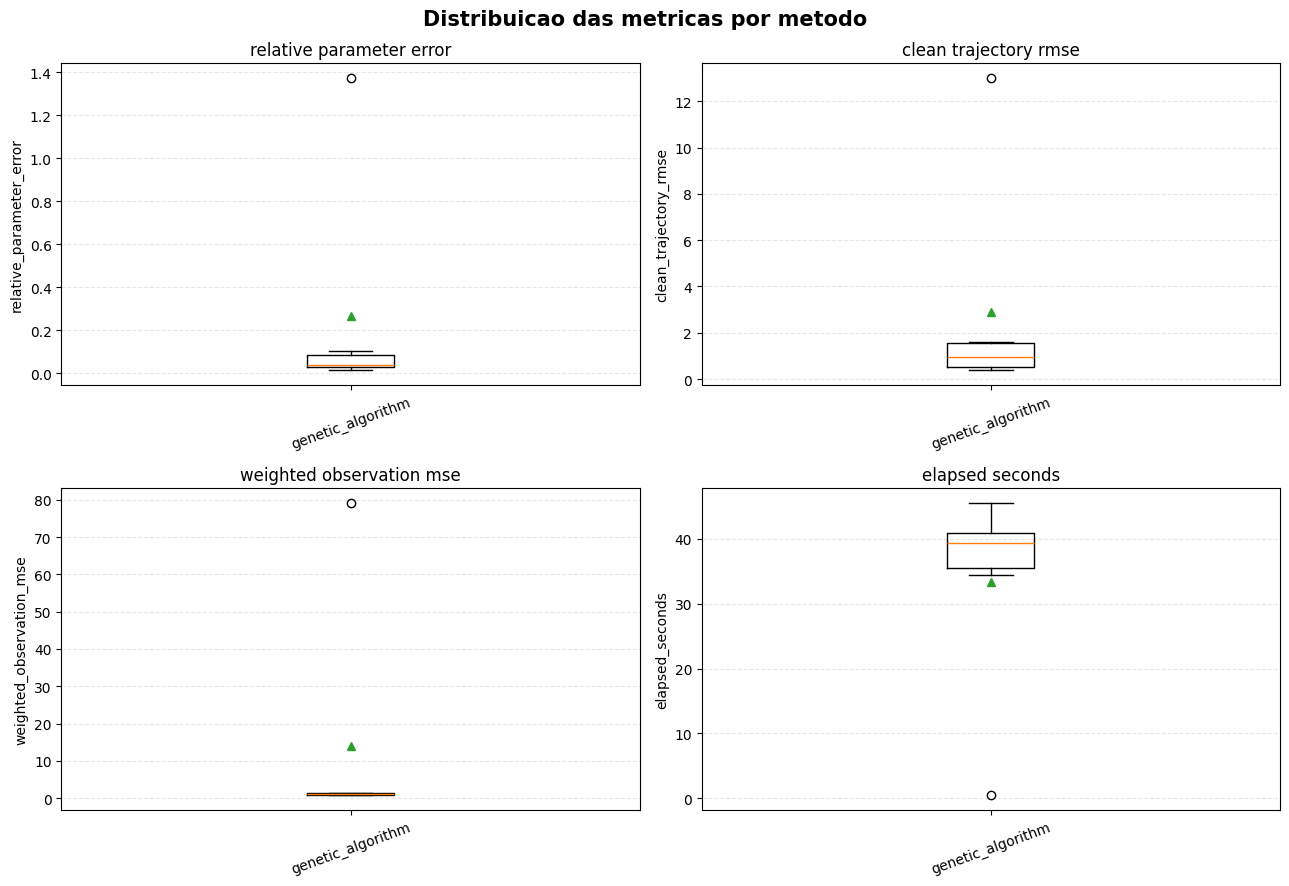

In [5]:
def boxplot_by_method(frame, metric, axis):
    methods = sorted(frame["method"].unique())
    values = [frame.loc[frame["method"] == method, metric].dropna() for method in methods]
    axis.boxplot(values, tick_labels=methods, showmeans=True)
    axis.set_title(metric.replace("_", " "))
    axis.set_ylabel(metric)
    axis.tick_params(axis="x", rotation=20)
    axis.grid(axis="y", linestyle="--", alpha=0.3)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for axis, metric in zip(axes.flat, metric_columns, strict=True):
    boxplot_by_method(results, metric, axis)
fig.suptitle("Distribuicao das metricas por metodo", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

## Efeito do nivel de ruido

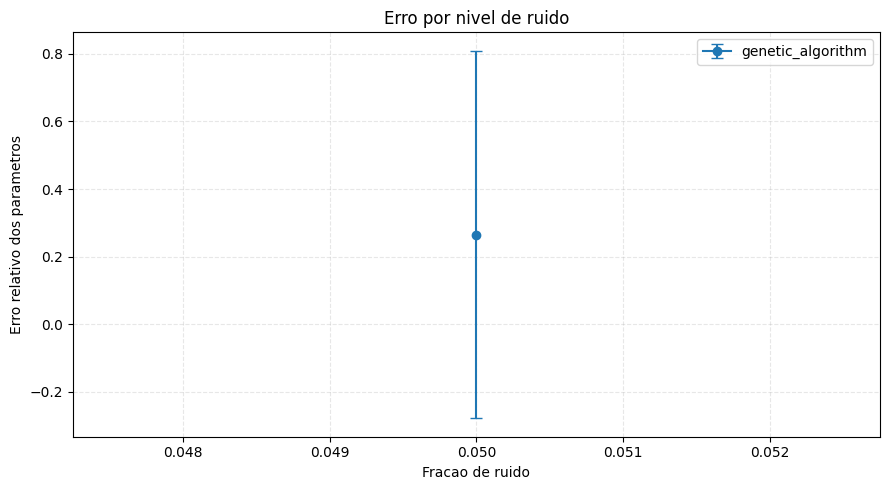

,method,noise_fraction,mean,std,count
0,genetic_algorithm,0.05,0.2654,0.5439,6


In [6]:
noise_summary = (
    results.groupby(["method", "noise_fraction"])["relative_parameter_error"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

fig, axis = plt.subplots(figsize=(9, 5))
for method, group in noise_summary.groupby("method"):
    group = group.sort_values("noise_fraction")
    axis.errorbar(
        group["noise_fraction"],
        group["mean"],
        yerr=group["std"].fillna(0.0),
        marker="o",
        capsize=4,
        label=method,
    )
axis.set_xlabel("Fracao de ruido")
axis.set_ylabel("Erro relativo dos parametros")
axis.set_title("Erro por nivel de ruido")
axis.grid(linestyle="--", alpha=0.3)
axis.legend()
plt.tight_layout()
plt.show()

noise_summary.round(4)

## Decomposicao da variabilidade

A primeira tabela mede a variacao entre sementes do otimizador para as mesmas observacoes. A segunda mede a variacao entre realizacoes de ruido, depois de resumir as sementes do otimizador.

In [7]:
optimizer_variability = (
    results.groupby(["method", "case_id", "noise_fraction", "noise_replicate"])["relative_parameter_error"]
    .agg(["count", "mean", "std"])
    .rename(columns={"std": "optimizer_seed_std"})
    .reset_index()
)

observation_means = (
    results.groupby(["method", "case_id", "noise_fraction", "noise_replicate"])["relative_parameter_error"]
    .mean()
    .reset_index(name="mean_over_optimizer_seeds")
)
observation_variability = (
    observation_means.groupby(["method", "case_id", "noise_fraction"])["mean_over_optimizer_seeds"]
    .agg(["count", "mean", "std"])
    .rename(columns={"std": "noise_replicate_std"})
    .reset_index()
)

display(optimizer_variability.round(4))
display(observation_variability.round(4))

,method,case_id,noise_fraction,noise_replicate,count,mean,optimizer_seed_std
0,genetic_algorithm,0,0.05,0,6,0.2654,0.5439


,method,case_id,noise_fraction,count,mean,noise_replicate_std
0,genetic_algorithm,0,0.05,1,0.2654,NaN


## Parametros verdadeiros e estimados

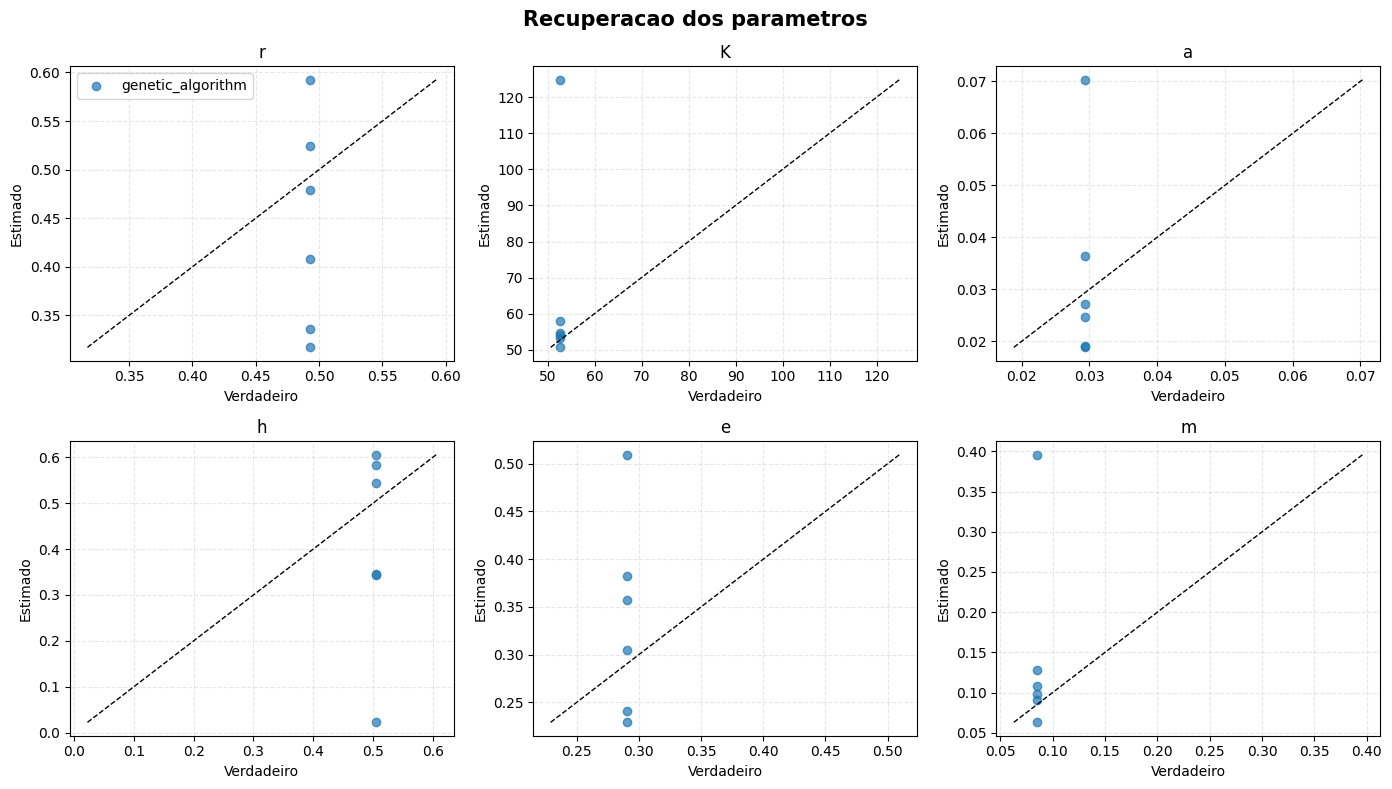

In [8]:
parameter_names = ["r", "K", "a", "h", "e", "m"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for axis, parameter in zip(axes.flat, parameter_names, strict=True):
    true_column = f"{parameter}_true"
    estimated_column = f"{parameter}_estimated"
    for method, group in results.groupby("method"):
        axis.scatter(group[true_column], group[estimated_column], alpha=0.7, label=method)
    minimum = min(results[true_column].min(), results[estimated_column].min())
    maximum = max(results[true_column].max(), results[estimated_column].max())
    axis.plot([minimum, maximum], [minimum, maximum], "k--", linewidth=1)
    axis.set_title(parameter)
    axis.set_xlabel("Verdadeiro")
    axis.set_ylabel("Estimado")
    axis.grid(linestyle="--", alpha=0.3)
axes[0, 0].legend()
fig.suptitle("Recuperacao dos parametros", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

## Historicos de convergencia

Arquivos de historico sao opcionais. Metodos sem iteracoes, como uma rede inversa apos o treinamento, podem simplesmente nao fornecer um historico por execucao.

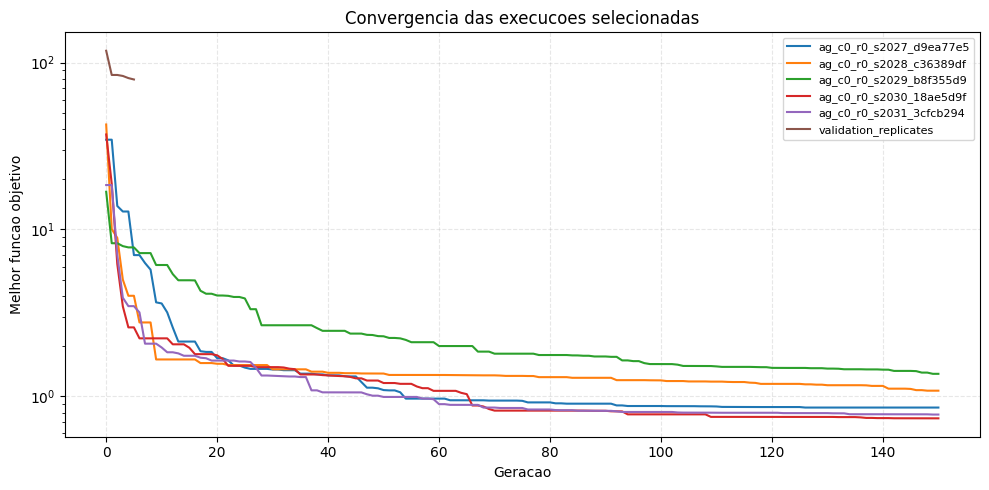

In [9]:
history_frames = []
for run_id in results["run_id"]:
    history_path = history_dir / f"{run_id}.csv"
    if history_path.exists():
        history = pd.read_csv(history_path)
        history["run_id"] = run_id
        history_frames.append(history)

if history_frames:
    histories = pd.concat(history_frames, ignore_index=True)
    fig, axis = plt.subplots(figsize=(10, 5))
    for run_id, history in histories.groupby("run_id"):
        axis.plot(history["generation"], history["best_objective"], label=run_id)
    axis.set_yscale("log")
    axis.set_xlabel("Geracao")
    axis.set_ylabel("Melhor funcao objetivo")
    axis.set_title("Convergencia das execucoes selecionadas")
    axis.grid(linestyle="--", alpha=0.3)
    axis.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print("Nenhum historico encontrado para as execucoes selecionadas.")